# Phase 8 — Ground-truth validation, outcome maturity & formal heterogeneity

Because the dataset is synthetic, we know the true effects. That lets us ask
the question real experiments can never answer: *does the pipeline recover
the truth?* This script also closes three gaps a skeptical reviewer would
raise about Phases 1-7:

  A. Ground-truth recovery   - do the CIs cover the true ATE / segment effects?
  B. Coverage simulation     - over many replications, do 95% CIs cover ~95%?
  C. Outcome maturity        - was the 14-day conversion window closed for
                               every user at analysis time?
  D. Formal HTE test         - treatment x segment interaction (likelihood
                               ratio test), instead of eyeballing per-segment p's
  E. Segment multiplicity    - Holm correction across ALL segment tests
  F. Skewed secondary metric - does the watch-hours conclusion survive
                               a log transform / bootstrap?

Script version: python notebooks/08_validation_and_heterogeneity.py

In [1]:
import os
import sys
import warnings
from pathlib import Path

# The analysis code uses paths relative to the project root, so run from there.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", message="Glyph .* missing from font")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

from src.analysis.frequentist import holm_bonferroni, two_proportion_test, welch_t_test
from src.analysis.sanity_checks import outcome_maturity
from src.analysis.segmentation import segment_lifts
from src.data.loader import load_experiment
from src.data.simulate import SimConfig, simulate_experiment

FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def ate_test(df: pd.DataFrame):
    c, t = df[df["group"] == "control"], df[df["group"] == "treatment"]
    return two_proportion_test(
        int(c["converted"].sum()), len(c), int(t["converted"].sum()), len(t)
    )

## A. Ground-truth recovery (same dataset as Phases 1-7)

The dataset is synthetic, so the true effect for every user is known. Do the
estimated effects and their 95% CIs cover the truth, overall and by segment?

=== A. Ground-truth recovery (data/experiment.csv, seed 42) ===


            effect  true_pp  est_pp  ci_lo  ci_hi  covered
       OVERALL ATE     2.29    2.54   2.02   3.06     True
    device=Android     2.93    2.96   2.09   3.84     True
         device=TV     0.57    0.42  -1.21   2.06     True
        device=Web     1.24    1.96   0.92   3.00     True
        device=iOS     2.96    3.24   2.30   4.18     True
is_returning=False     1.90    2.26   1.69   2.82     True
 is_returning=True     3.46    3.29   2.13   4.45     True

True ATE +2.29pp vs estimated +2.54pp. Note the pre-experiment brief asked for >=1pp; the simulated truth is larger,
so this is a clear win by construction. Real effects are rarely this big - a +12% relative lift in real life deserves extra bug-hunting.


7 of 7 CIs cover the true effect
Saved -> reports/figures/08_ground_truth_recovery.png


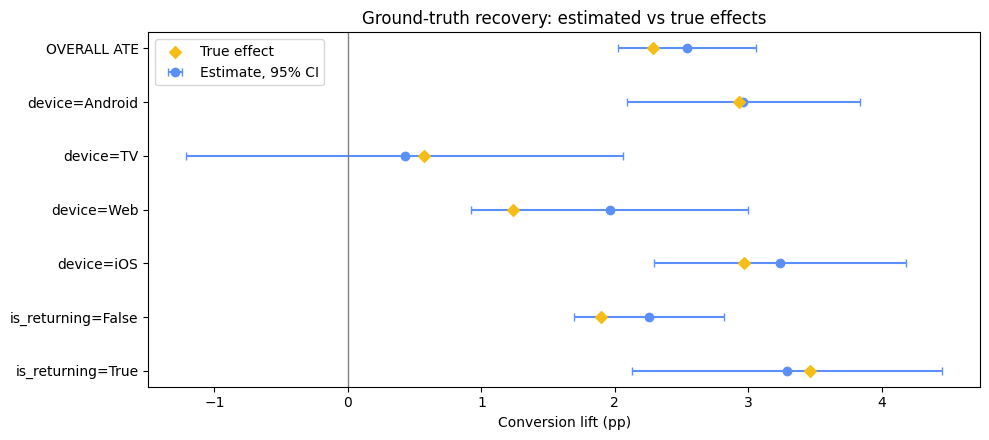

In [2]:
print("=== A. Ground-truth recovery (data/experiment.csv, seed 42) ===")
df_truth, truth = simulate_experiment(SimConfig(), return_truth=True)
lift = truth["p1"] - truth["p0"]
df = load_experiment("data/experiment.csv")
assert (df["converted"].values == df_truth["converted"].values).all(), \
    "data/experiment.csv is out of sync with simulate.py - regenerate it"

res = ate_test(df)
true_ate = lift.mean()
rows = [("OVERALL ATE", true_ate, res.effect_absolute, res.ci_lower, res.ci_upper)]
for col in ["device", "is_returning"]:
    true_seg = lift.groupby(df[col]).mean()
    est = segment_lifts(df, col, "converted").set_index("segment")
    for seg, tv in true_seg.items():
        rows.append((f"{col}={seg}", tv, est.loc[seg, "effect_abs"],
                     est.loc[seg, "ci_lower"], est.loc[seg, "ci_upper"]))
rec = pd.DataFrame(rows, columns=["effect", "true_pp", "est_pp", "ci_lo", "ci_hi"])
rec[["true_pp", "est_pp", "ci_lo", "ci_hi"]] *= 100
rec["covered"] = (rec["ci_lo"] <= rec["true_pp"]) & (rec["true_pp"] <= rec["ci_hi"])
print(rec.round(2).to_string(index=False))
print(f"\nTrue ATE {true_ate * 100:+.2f}pp vs estimated {res.effect_absolute * 100:+.2f}pp. "
      "Note the pre-experiment brief asked for >=1pp; the simulated truth is larger,\n"
      "so this is a clear win by construction. Real effects are rarely this big - a "
      "+12% relative lift in real life deserves extra bug-hunting.")

fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(rec))[::-1]
ax.errorbar(rec["est_pp"], y, xerr=[rec["est_pp"] - rec["ci_lo"], rec["ci_hi"] - rec["est_pp"]],
            fmt="o", color="#5B8FF9", ecolor="#5B8FF9", capsize=3, label="Estimate, 95% CI")
ax.scatter(rec["true_pp"], y, marker="D", color="#F6BD16", zorder=3, label="True effect")
ax.axvline(0, color="gray", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(rec["effect"])
ax.set_xlabel("Conversion lift (pp)")
ax.set_title("Ground-truth recovery: estimated vs true effects")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "08_ground_truth_recovery.png", dpi=140, bbox_inches="tight")
print(f"{int(rec['covered'].sum())} of {len(rec)} CIs cover the true effect")
print("Saved -> reports/figures/08_ground_truth_recovery.png")

## B. Coverage simulation: do nominal 95% CIs cover the truth ~95% of time?

One dataset can cover the truth by luck. Re-simulate the experiment 300 times
with new seeds and count how often the 95% CI covers the true ATE.

In [3]:
print("\n=== B. CI coverage over 300 replications (n=20,000 each) ===")
N_REPS, covered, errors = 300, 0, []
for seed in range(1000, 1000 + N_REPS):
    d, tr = simulate_experiment(SimConfig(n_users=20_000, seed=seed), return_truth=True)
    r = ate_test(d)
    t_ate = (tr["p1"] - tr["p0"]).mean()
    covered += r.ci_lower <= t_ate <= r.ci_upper
    errors.append(r.effect_absolute - t_ate)
print(f"Coverage of true ATE: {covered / N_REPS:.1%} (nominal 95%)")
print(f"Mean estimation error: {np.mean(errors) * 100:+.3f}pp "
      f"(SD {np.std(errors) * 100:.3f}pp)")
print("Reading: coverage near 95% means the CI machinery is calibrated; a clearly\n"
      "lower number would mean the SE is understated. The simulator's SRM leak is\n"
      "random within Android, so it does not bias the ATE.")


=== B. CI coverage over 300 replications (n=20,000 each) ===


Coverage of true ATE: 95.3% (nominal 95%)
Mean estimation error: -0.012pp (SD 0.579pp)
Reading: coverage near 95% means the CI machinery is calibrated; a clearly
lower number would mean the SE is understated. The simulator's SRM leak is
random within Android, so it does not bias the ATE.


## C. Outcome maturity

Conversion is measured over a 14-day trial. A user who signed up less than
14 days before the analysis date has not finished the window, so their
outcome is censored.

In [4]:
print("\n=== C. Outcome maturity (14-day conversion window) ===")
for label, when in [("memo-date draft (2026-05-08)", "2026-05-08"),
                    ("2026-05-15 data pull", "2026-05-15")]:
    m = outcome_maturity(df, when, window_days=14)
    print(f"{label}: {m['matured_share']:.1%} of users matured "
          f"({m['n_immature']:,} immature); all matured on {m['all_matured_on']:%Y-%m-%d}")
print("Reading: signups run Apr 1-28, so the last 14-day window closes ~May 12. "
      "Analysing before that\ncensors late cohorts. The memo is dated after "
      "May 12 for this reason; in a real project, restrict to matured\ncohorts "
      "or wait. Weekly ATEs for week 4 are the ones most exposed to this.")


=== C. Outcome maturity (14-day conversion window) ===
memo-date draft (2026-05-08): 82.1% of users matured (17,883 immature); all matured on 2026-05-12
2026-05-15 data pull: 100.0% of users matured (0 immature); all matured on 2026-05-12
Reading: signups run Apr 1-28, so the last 14-day window closes ~May 12. Analysing before that
censors late cohorts. The memo is dated after May 12 for this reason; in a real project, restrict to matured
cohorts or wait. Weekly ATEs for week 4 are the ones most exposed to this.


## D. Formal heterogeneity: LR test of treatment x segment interaction

Per-segment p-values in Phase 5 don't test whether the effect DIFFERS between
segments. A treatment x segment interaction in a logit model, compared with a
likelihood-ratio test, does.

In [5]:
print("\n=== D. Formal HTE test (logit, LR test of interaction) ===")
df["treat"] = (df["group"] == "treatment").astype(int)
df["returning"] = df["is_returning"].astype(int)
base = "converted ~ treat + C(device) + C(country) + C(source) + returning"
m0 = smf.logit(base, data=df).fit(disp=0)
for term, name in [("treat:C(device)", "device"), ("treat:returning", "is_returning"),
                   ("treat:C(country)", "country"), ("treat:C(source)", "source")]:
    m1 = smf.logit(f"{base} + {term}", data=df).fit(disp=0)
    lr = 2 * (m1.llf - m0.llf)
    dof = int(m1.df_model - m0.df_model)
    print(f"  treat x {name:<12} LR chi2={lr:7.2f}, df={dof}, p={stats.chi2.sf(lr, dof):.4g}")
print("Reading: only the device interaction is significant (p~0.01). The planted\n"
      "returning-user bump is tiny on the log-odds scale (+0.04), so there is no\n"
      "detectable returning x treatment interaction: returning users show a larger\n"
      "lift in percentage points mostly because their baseline conversion is higher\n"
      "(their RELATIVE lift is actually lower). Country and source were given no\n"
      "interaction, and the tests agree. Per-segment differences in the forest plot\n"
      "outside device should therefore not be over-interpreted.")


=== D. Formal HTE test (logit, LR test of interaction) ===


  treat x device       LR chi2=  10.75, df=3, p=0.01315


  treat x is_returning LR chi2=   0.05, df=1, p=0.8231


  treat x country      LR chi2=   2.89, df=4, p=0.5763


  treat x source       LR chi2=   2.83, df=3, p=0.4188
Reading: only the device interaction is significant (p~0.01). The planted
returning-user bump is tiny on the log-odds scale (+0.04), so there is no
detectable returning x treatment interaction: returning users show a larger
lift in percentage points mostly because their baseline conversion is higher
(their RELATIVE lift is actually lower). Country and source were given no
interaction, and the tests agree. Per-segment differences in the forest plot
outside device should therefore not be over-interpreted.


## E. Multiplicity across all segment tests

Phase 5 ran 15 segment tests. Holm's step-down correction controls the
family-wise error rate across all of them.

In [6]:
print("\n=== E. Holm correction across all segment-level tests ===")
seg_rows = []
for col in ["device", "country", "source", "is_returning"]:
    s = segment_lifts(df, col, "converted").assign(dimension=col)
    seg_rows.append(s)
seg = pd.concat(seg_rows, ignore_index=True)
seg["survives_holm"] = holm_bonferroni(seg["p_value"].tolist())
print(seg[["dimension", "segment", "effect_abs", "p_value", "significant",
           "survives_holm"]].assign(effect_abs=lambda x: (x.effect_abs * 100).round(2))
      .to_string(index=False))
print(f"\n{len(seg)} segment tests; {int(seg['significant'].sum())} significant "
      f"uncorrected, {int(seg['survives_holm'].sum())} after Holm.")


=== E. Holm correction across all segment-level tests ===
   dimension     segment  effect_abs      p_value  significant  survives_holm
      device         iOS        3.24 1.628608e-11         True           True
      device     Android        2.96 3.252709e-11         True           True
      device         Web        1.96 2.185269e-04         True           True
      device          TV        0.42 6.112739e-01        False          False
     country          AU        3.39 1.654916e-04         True           True
     country       Other        2.87 2.216921e-07         True           True
     country          US        2.52 2.500733e-10         True           True
     country          UK        2.27 9.892752e-04         True           True
     country          CA        1.64 4.646138e-02         True          False
      source    referral        3.48 4.278137e-07         True           True
      source paid_social        2.61 6.067786e-06         True           True
     

## F. Skewed secondary metric

Watch hours are right-skewed (gamma-shaped). Does the Welch t-test result
from Phase 3 survive a bootstrap CI, a log transform and a rank test?

In [7]:
print("\n=== F. trial_watch_hours: skew-robust checks ===")
c = df.loc[df["group"] == "control", "trial_watch_hours"].values
t = df.loc[df["group"] == "treatment", "trial_watch_hours"].values
print(f"skewness (control): {stats.skew(c):.2f}")
w = welch_t_test(c, t, name="watch_hours")
print(f"Welch mean diff: {w.effect_absolute:+.3f}h  CI [{w.ci_lower:+.3f}, {w.ci_upper:+.3f}]")
rng = np.random.default_rng(0)
boot = [rng.choice(t, len(t)).mean() - rng.choice(c, len(c)).mean() for _ in range(2000)]
print(f"Bootstrap (2k) CI: [{np.percentile(boot, 2.5):+.3f}, {np.percentile(boot, 97.5):+.3f}]")
lt = np.log1p(t).mean() - np.log1p(c).mean()
print(f"Log1p mean diff: {lt:+.3f} (~{(np.exp(lt) - 1) * 100:.1f}% geometric-mean lift)")
mw = stats.mannwhitneyu(t, c, alternative="two-sided")
print(f"Mann-Whitney p = {mw.pvalue:.3g}")
print("Reading: all four agree on direction and significance, so the Welch result\n"
      "in Phase 3 is not an artifact of the gamma-shaped distribution.")


=== F. trial_watch_hours: skew-robust checks ===
skewness (control): 1.59
Welch mean diff: +0.873h  CI [+0.822, +0.924]


Bootstrap (2k) CI: [+0.824, +0.925]
Log1p mean diff: +0.126 (~13.4% geometric-mean lift)
Mann-Whitney p = 2.47e-200
Reading: all four agree on direction and significance, so the Welch result
in Phase 3 is not an artifact of the gamma-shaped distribution.
